##**5.1 합성곱 신경망**

: 이미지 전체를 한 번에 계산하는 것이 아닌 이미지의 국소적 부분을 계산함으로써 시간과 자원을 절약하여 이미지의 세밀한 부분까지 분석할 수 있는 신경망

###**5.1.1 합성곱층의 필요성**

> 이미지나 영상을 처리하는 데 유용

: 이미지 분석은 다음 그림과 같은 3x3 배열을 오른쪽과 같이 펼쳐서 각 픽셀에 가중치를 곱하여 은닉층으로 전달하게 됨. 하지만 그림에서 보이는 것처럼 이미지를 펼처서 분석하면 데이터의 공간적 구조를 무시하게 되는데, 이것을 방지하려고 도임된 것이 합성곱층

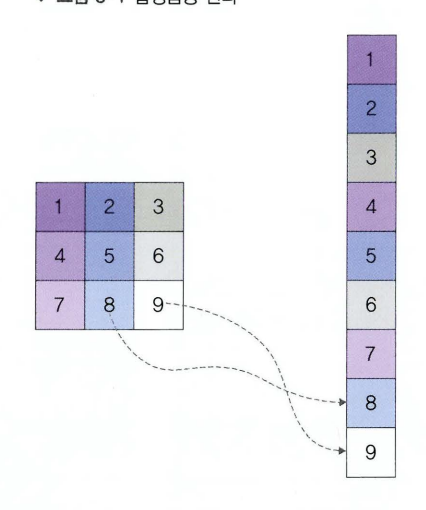

###**5.1.2 합성곱 신경망 구조**

: 음성 인식이나 이미지/영상 인식에서 주로 사용되는 신경망

- 다차원 배열 데이터를 처리하도록 구성되어 컬러 이미지 같은 다차원 배열 처리에 특화되어 있음

[계층]

1. 입력층
2. 합성곱층
3. 풀링층
4. 완전연결층
5. 출력층

- 합성곱 신경망은 합성곱층과 풀링층을 거치면서 입력 이미지의 주요 특성 벡터를 추출
- 그 후 추출된 주요 특성 벡터들은 완전연결층을 거치면서 1차원 벡터로 변환
- 마지막으로 출력층에서 활성화 함수인 소프트맥스 함수를 사용하여 최종 결과가 출력

<br>

**입력층**

: 입력 이미지 데이터가 최초로 거치게 되는 계층

- 이미지는 단순 1차원 데이터가 아닌 높이, 너비, 채널의 값을 갖는 3차원 데이터
- 이 때 채널은 이미지가 그레이스케일이면 1 값을 가지며, 컬러면 3 값을 가짐 (RGB = 3)

**합성곱층**

: 입력 데이터에서 특성을 추출하는 역할

- 입력 이미지가 들어왔을 때 이미지에 대한 특성을 감지하기 위해 커널이나 필터 사용
- 커널/필터는 이미지의 모든 영역을 훑으면서 특성을 추출하게 되는데, 이렇게 추출된 결과물이 특성 맵
- 커널은 3x3, 5x5 크기로 적용되는 것이 일반적이며, 스트라이드라는 지정된 간격에 따라 순차적으로 이동

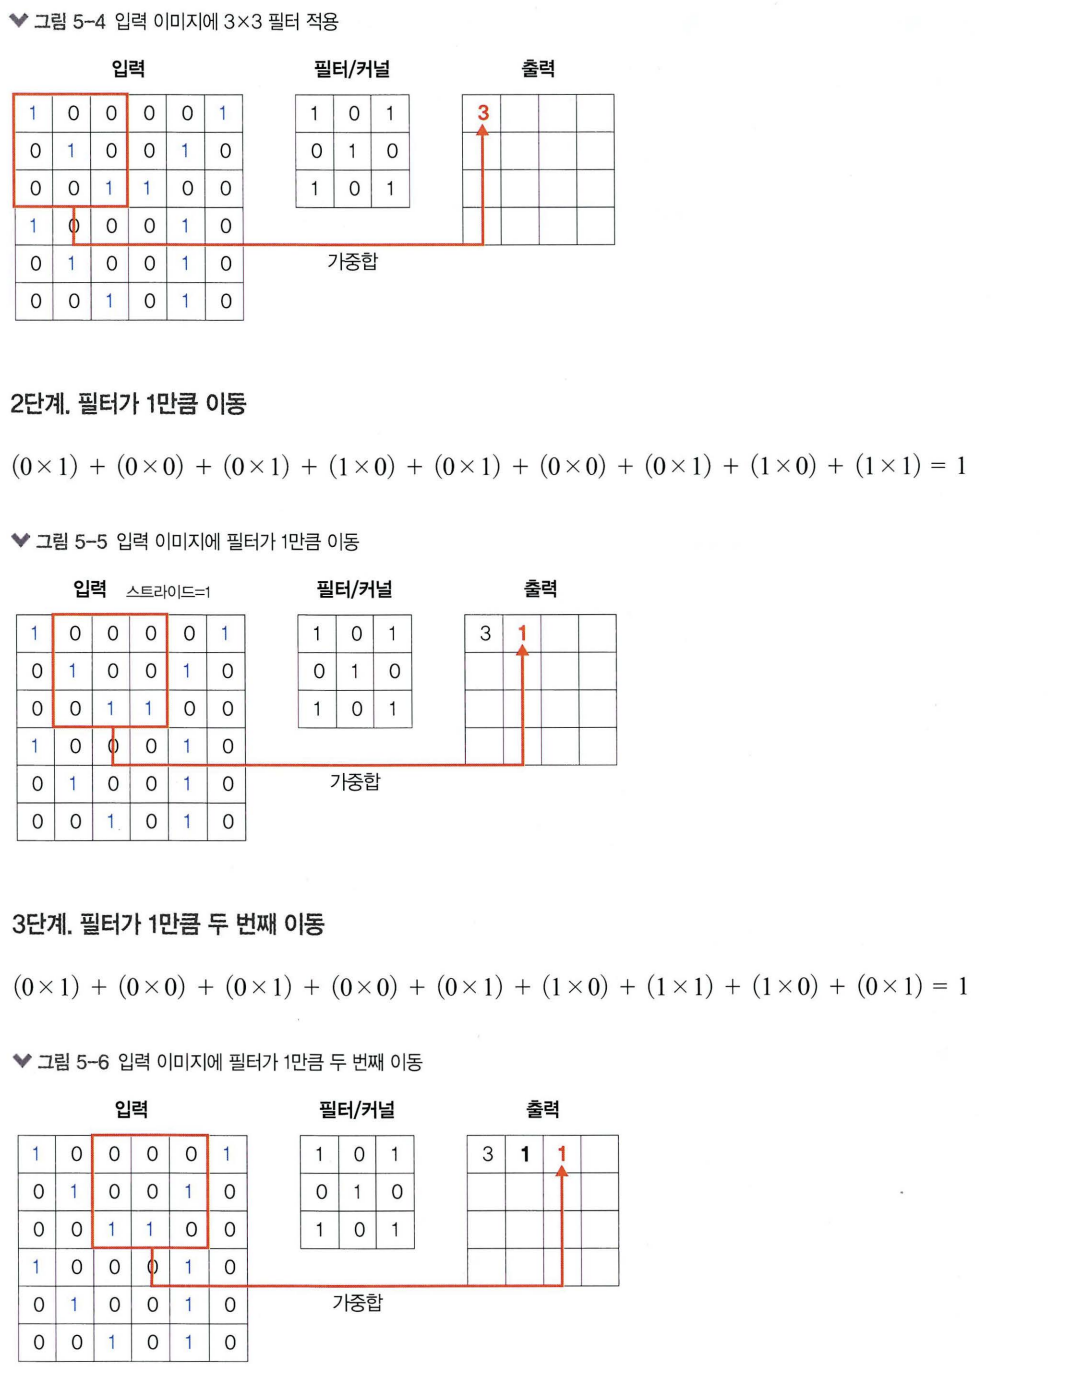


- 앞의 그림에서는 이미지 크기가 (6,6,1)이며,  3x3 크기의 커널/필터가 스트라이드 1 간격으로 이동하면서 합성곱 연산을 수행하는 것을 보여줌
- 이렇게 커널은 스트라이드 간격만큼 순회하면서 모든 입력 값과의 합성곱 연산으로 새로운 특성 맵을 만들게 됨
- 앞의 그림과 같이 커널과 스트라이드의 상호 작용으로 원본 크기가 (4,4,1) 크기의 특성 맵으로 줄어듬
- 컬러 이미지의 합성곱에서는 필터 채널이 3, RGB 각각에 서로 다른 가중치로 합성곱을 적용한 후 결과를 더해줌
- 필터가 두 개 이상이면 필터 각각은 특성 추출 결과의 채널이 됨

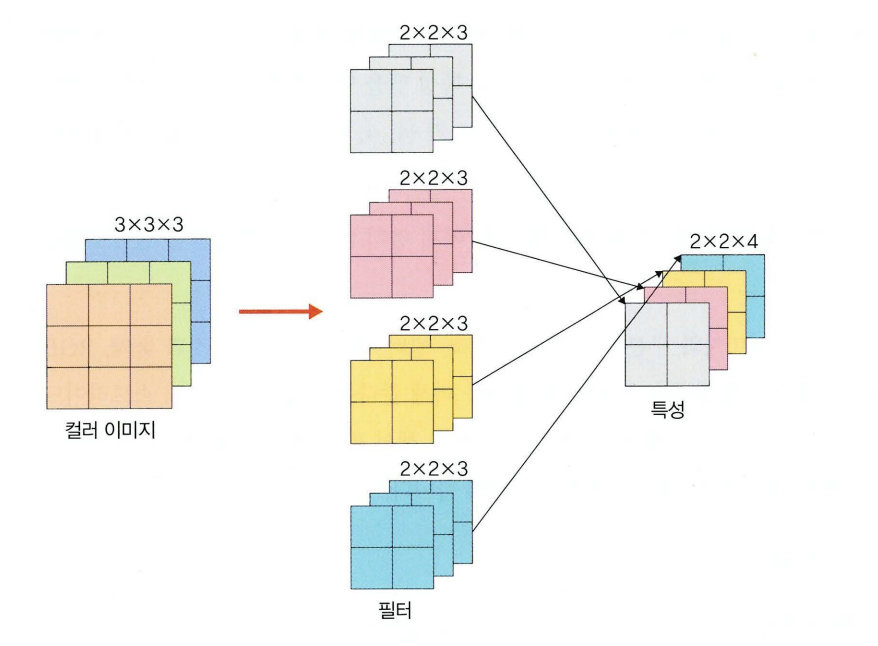

**풀링층**
: 합성곱층과 유사하게 특성 맵의 차원을 다운 샘플링(이미지 축소)하여 연산량을 감소시키고, 주요한 특성 벡터를 추출하여 학습을 효과적으로 할 수 있게 함

- 최대 풀링: 대상 영역에서 최댓값을 추출
- 평균 풀링: 대상 영역에서 평균을 반환

: 하지만 대부분의 합성곱 신경망에서는 최대 풀링이 사용되는데, 평균 풀링은 각 커널 값을 평균화시켜 중요한 가중치를 갖는 값의 특성이 희미해질 수 있기 떄문

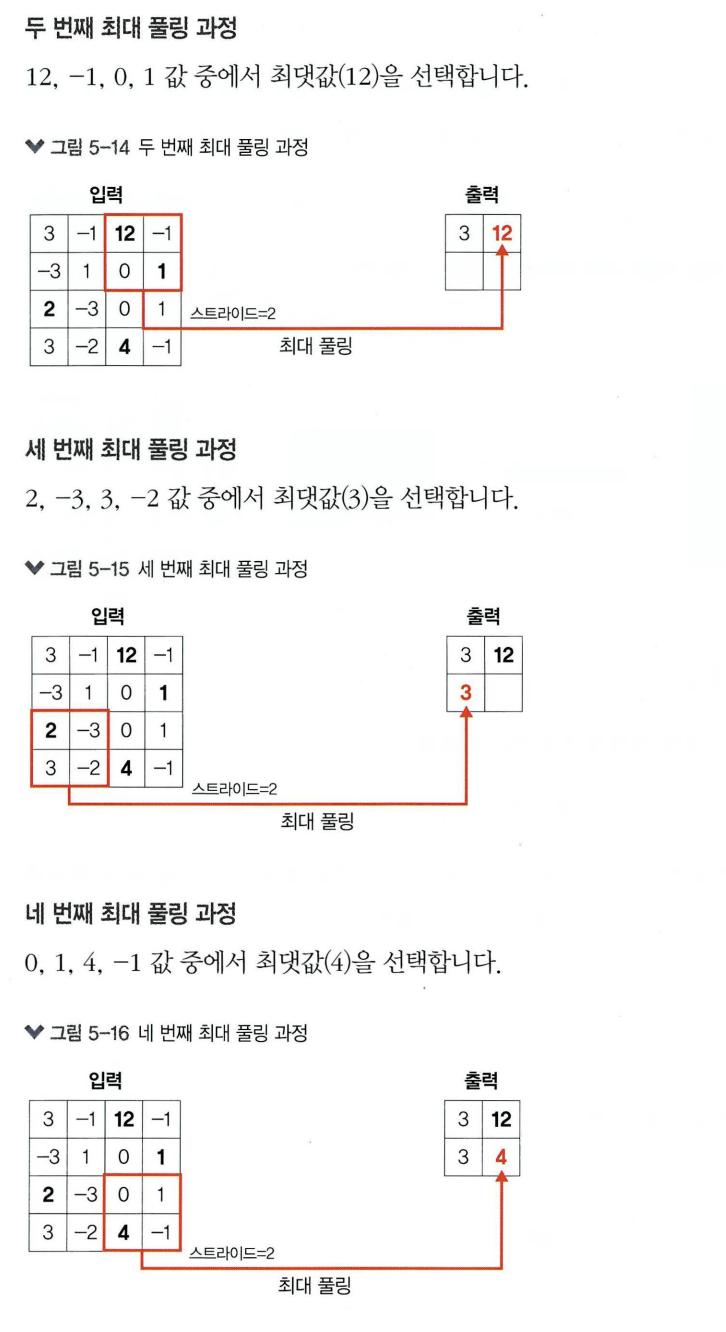


- 평균 폴링의 계산과정은 최대 풀링과 유사한 방식으로 진행하되 각 필터의 평균으로 계산

**완전연결층**

: 합성곱층과 풀링층을 거치면서 차원이 축소된 특성 맵은 최종적으로 완전연경층으로 전달. 이 과정에서 이미지는 3차원 벡터에서 1차원 벡터로 펼쳐지게 됨

**출력층**

: 소프트맥스 활성화 함수가 사용되는데, 입력받은 값을 0~1 사이의 값으로 출력. 따라서 마지막 출력층의 소프트맥스 함수를 사용하여 임지가 각 레이블에 속할 확률 값이 출력되며, 이때 가장 높은 확률 값을 갖는 레이블이 최종 값으로 선정

<br>

###**5.1.3 1D, 2D, 3D 합성곱**

**1D 합성곱**

: 필터가 시간을 축으로 좌우로만 이동할 수 있는 합성곱

- 따라서 입력(W)과 필터(k)에 대한 출력은 W.

![image](images/image_55.png)

**2D 합성곱**

: 필터가 다음 그림과 같이 방향 두 개로 움직이는 형태. 즉 입력(W,H)과 필터 (k,k)에 대한 출력은 (W,H)가 됨

![image](images/image_56.png)

**3D 합성곱**

: 필터가 움직이는 방향이 3개. 입력 (W,H,L)에 대해 필터 (k,k,d)를 적용하면 출력으로 (W,H,L)을 갖는 형태. d<L을 유지하는 것이 중요




![image](images/image_57.png)

**3D 입력을 갖는 2D 합성곱**

: 입력이 3D 형태임에도 출력 형태가 3D가 아닌 2D 행렬을 취하는 것

- 필터에 대한 길이(L)가 입력 채널의 길이(L)와 같아야 하기 때문에 이와 같은 합성곱 형태가 만들어짐.
- 즉, 입력(W,H,L)에 필터 (k,k,L)를 적용하면 출력은 (W,H)가 됨

![image](images/image_58.png)

**1x1 합성곱**

: 3D 형태로 입력됨. 즉, 입력 (W, H, L) 에 필터 (1, 1, L)를 적용하면 출력은
(W, H)가 됨
- 채널 수를 조정해서 연산량이 감소되는 효과가 있음

![image](images/image_59.png)
